In [1]:
import math
import torch
import matplotlib.pyplot as plt

from freqsde import VEConvMixSDE   # adjust to your filename

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

device: cuda


In [9]:
# Load .npy file
import numpy as np
arr = np.load("/gpfs/data/ssa/users/d634375/FourierDiffusionConvolutiveSourceSeparation/data/sim/filters/filters.npy", allow_pickle=True)

max_length = max(len(x) for x in arr)

N_fft = 1000 + max_length  # or whatever you intend

tensor = torch.stack([
    torch.fft.rfft(torch.tensor(x, dtype=torch.float32), n=N_fft)
    for x in arr
])

In [11]:
tensor.shape

torch.Size([3, 508])

In [12]:
K     = 2
N_fft = 8
T     = 1.0
N     = 100
alpha = 5.0
beta  = 5.

sde = VEConvMixSDE(
    ndim      = K * N_fft,
    alpha     = alpha,
    beta      = beta,
    sigma_min = 0.05,
    sigma_max = 0.5,
    steps     = 1000,
    T         = T,
    N         = N,
)

torch.manual_seed(0)
kernels = torch.randn(K, N_fft, dtype=torch.complex64) + 1.0

sde.get_mix_mat(kernels, N_fft)
sde.send_to(DEVICE)

In [14]:
kernels.shape

torch.Size([2, 8])

In [3]:
B = 4
t = torch.linspace(1e-4, T, B, device=DEVICE)

Ft = sde.get_Ft(t)
exp_Ft_integrale = sde.get_exp_Ft_integral(t)

print('F(t) shape :', Ft.shape)   # (B, K*N_fft, K*N_fft)
print('exp(/Fs(t)) shape :', exp_Ft_integrale.shape)   # (B, K*N_fft, K*N_fft)

# should be close to identity
t_zero = torch.tensor([0], device=DEVICE)
exp_F0     = sde.get_exp_Ft_integral(t_zero)[0]
eye    = torch.eye(K * N_fft, device=DEVICE)
print(f'||exp(/F(s))(t=0) - I|| = {(exp_F0 - eye).norm().item():.4f}   (should be ~0)')

F(t) shape : torch.Size([4, 16, 16])
exp(/Fs(t)) shape : torch.Size([4, 16, 16])
||exp(/F(s))(t=0) - I|| = 0.0000   (should be ~0)


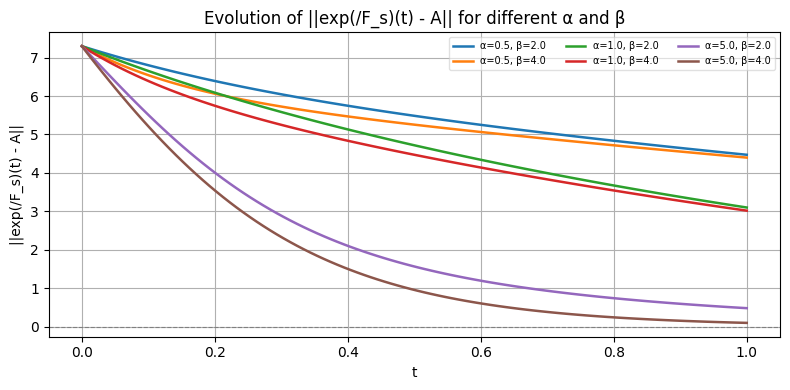

In [4]:
import matplotlib.pyplot as plt
import torch
import itertools

alphas = [0.5, 1.0, 5.0]
betas  = [2.0, 4.0]

t_grid = torch.linspace(1e-4, sde.T, 100, device=DEVICE)

plt.figure(figsize=(8, 4))

for alpha, beta in itertools.product(alphas, betas):

    sde_ab = VEConvMixSDE(
        ndim      = sde.ndim,
        alpha     = alpha,
        beta      = beta,
        sigma_min = sde.sigma_min,
        sigma_max = sde.sigma_max,
        steps     = sde.steps,
        T         = sde.T,
        N         = sde.N,
    )
    sde_ab.get_mix_mat(kernels, sde.N_fft).send_to(DEVICE)

    distances = []
    for t_val in t_grid:
        t_i   = t_val.unsqueeze(0)
        exp_F = sde_ab.get_exp_Ft_integral(t_i)[0]
        distances.append((exp_F - sde_ab.A).norm().item())

    plt.plot(t_grid.cpu().numpy(), distances, linewidth=1.8, label=f'α={alpha}, β={beta}')

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('t')
plt.ylabel('||exp(/F_s)(t) - A||')
plt.title('Evolution of ||exp(/F_s)(t) - A|| for different α and β')
plt.legend(fontsize=7, ncol=3, loc='upper right', framealpha=0.6)
plt.grid(True)
plt.tight_layout()
plt.show()

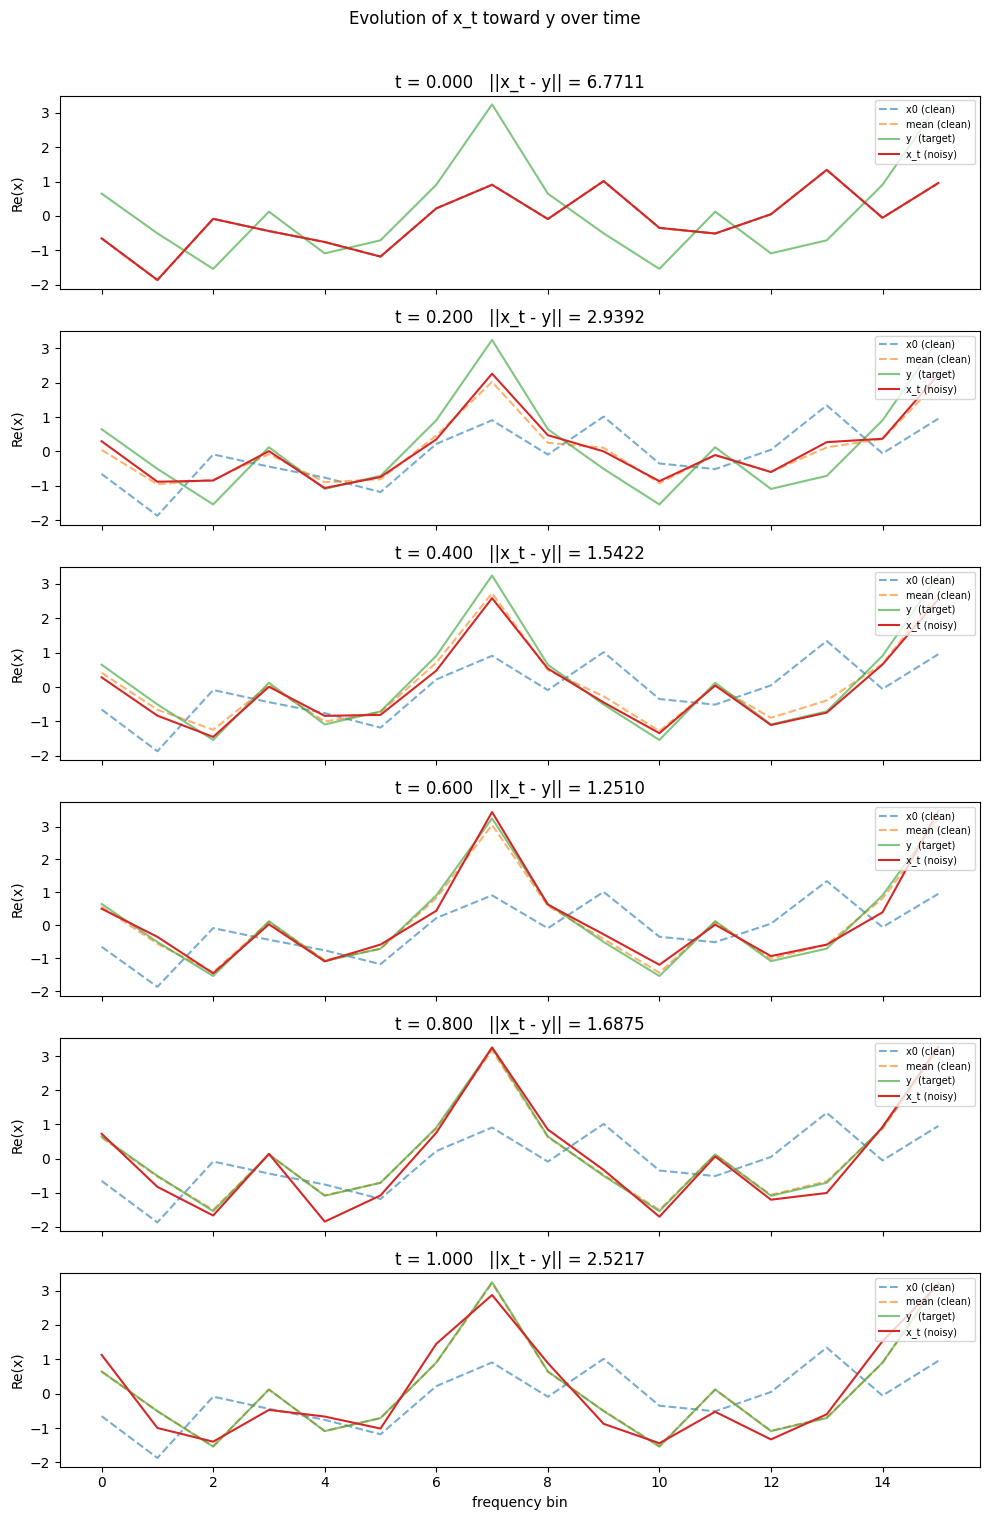

In [5]:
import matplotlib.pyplot as plt
import torch

B  = 4
D  = K * N_fft
n_times = 6                                                        # number of time steps to show
t_vals  = torch.linspace(1e-4, T, n_times, device=DEVICE)
t_vals  = t_vals.to(dtype=torch.complex64)

x0 = torch.randn(1, D, device=DEVICE, dtype=torch.complex64)      # single clean signal
y  = (sde.A @ x0.T).T                                          # mixed target  (1, D)

fig, axes = plt.subplots(n_times, 1, figsize=(10, 2.5 * n_times), sharex=True)

for idx, t_val in enumerate(t_vals):
    t_i        = t_val.unsqueeze(0)                                # (1,)
    mean, std  = sde.marginal_prob(x0, y, t_i)                    # (1,D), (1,D,D)
    z          = torch.randn_like(mean)
    x_t        =  mean + torch.einsum('bij,bj->bi', std, z)        # (1, D)

    ax = axes[idx]
    ax.plot(x0.real.squeeze().cpu(),    label='x0 (clean)',   linestyle='--', alpha=0.6)
    ax.plot(mean.real.squeeze().cpu(),    label='mean (clean)',   linestyle='--', alpha=0.6)
    ax.plot(y.real.squeeze().cpu(),     label='y  (target)',  linestyle='-',  alpha=0.6)
    ax.plot(x_t.real.squeeze().cpu(),   label='x_t (noisy)',  linestyle='-',  linewidth=1.5)
    ax.set_ylabel('Re(x)')
    ax.set_title(f't = {t_val.real.item():.3f}   ||x_t - y|| = {(x_t - y).norm().item():.4f}')
    ax.legend(fontsize=7, loc='upper right')

plt.suptitle('Evolution of x_t toward y over time', fontsize=12, y=1.01)
plt.xlabel('frequency bin')
plt.tight_layout()
plt.show()

In [6]:
shape   = (1, D)
x_prior = sde.prior_sampling(shape, y)
print('prior sample shape:', x_prior.shape)   # (B, D)

prior sample shape: torch.Size([1, 16])


In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np


# ============================================================
# Time embedding
# ============================================================

class GaussianFourierProjection(nn.Module):
    def __init__(self, embedding_size=256, scale=1.0):
        super().__init__()
        self.W = nn.Parameter(torch.randn(embedding_size) * scale)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)
        t_proj = t * self.W[None, :] * 2 * np.pi
        return torch.cat([torch.sin(t_proj), torch.cos(t_proj)], dim=-1)


class TimeEmbedding(nn.Module):
    def __init__(self, t_features, hidden_dim, T):
        super().__init__()
        self.fourier = GaussianFourierProjection(t_features, scale=1 / T)
        self.mlp = nn.Sequential(
            nn.Linear(2 * t_features, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )

    def forward(self, t):
        return self.mlp(self.fourier(t))


# ============================================================
# ResBlock 2D (time conditioned)
# ============================================================

class ResBlock2D(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)

        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)

        self.time_proj = nn.Linear(time_dim, out_ch)

        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(t).unsqueeze(-1).unsqueeze(-1)
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


# ============================================================
# Anisotropic Downsample (ONLY N dimension shrinks)
# ============================================================

class DownsampleN(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, kernel_size=(1, 4), stride=(1, 2), padding=(0, 1))

    def forward(self, x):
        return self.conv(x)


class UpsampleN(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.ConvTranspose2d(ch, ch, kernel_size=(1, 4), stride=(1, 2), padding=(0, 1))

    def forward(self, x):
        return self.conv(x)


# ============================================================
# Attention over full (K x N)
# ============================================================

class SelfAttention2D(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.heads = heads
        self.scale = (ch // heads) ** -0.5

        self.norm = nn.GroupNorm(8, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        B, C, K, N = x.shape

        h = self.norm(x)
        q, k, v = self.qkv(h).chunk(3, dim=1)

        def reshape(t):
            return t.reshape(B, self.heads, C // self.heads, K * N)

        q, k, v = reshape(q), reshape(k), reshape(v)

        attn = torch.softmax(
            (q.transpose(-2, -1) @ k) * self.scale,
            dim=-1
        )

        out = v @ attn.transpose(-2, -1)
        out = out.reshape(B, C, K, N)

        return x + self.proj(out)


# ============================================================
# Conditional UNet 2D (K small, N large)
# ============================================================

class UNet2DKSmallNLarge(nn.Module):
    def __init__(
        self,
        in_channels=2,
        out_channels=2,
        base_channels=64,
        depth=3,
        time_dim=256,
        T=1000,
        use_attention=True,
    ):
        super().__init__()

        self.time = TimeEmbedding(time_dim, time_dim, T)

        # conditioning projection
        self.cond_proj = nn.Sequential(
            nn.Conv2d(2, base_channels, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_channels, base_channels, 3, padding=1),
        )

        self.in_conv = nn.Conv2d(in_channels, base_channels, 3, padding=1)

        # ---------------- Encoder ----------------
        self.down_blocks = nn.ModuleList()
        self.downsamples = nn.ModuleList()

        ch = base_channels
        skips = []

        for i in range(depth):
            out_ch = base_channels * (2 ** i)

            self.down_blocks.append(ResBlock2D(ch, out_ch, time_dim))

            # IMPORTANT: only downsample N, NOT K
            self.downsamples.append(DownsampleN(out_ch))

            skips.append(out_ch)
            ch = out_ch

        # ---------------- Bottleneck ----------------
        self.mid1 = ResBlock2D(ch, ch, time_dim)
        self.attn = SelfAttention2D(ch) if use_attention else nn.Identity()
        self.mid2 = ResBlock2D(ch, ch, time_dim)

        # ---------------- Decoder ----------------
        self.upsamples = nn.ModuleList()
        self.up_blocks = nn.ModuleList()

        for i in reversed(range(depth)):
            skip_ch = skips[i]
            out_ch = base_channels * (2 ** i)

            self.upsamples.append(UpsampleN(ch))
            self.up_blocks.append(ResBlock2D(ch + skip_ch, out_ch, time_dim))

            ch = out_ch

        self.out_conv = nn.Conv2d(ch, out_channels, 3, padding=1)

    def forward(self, x, t):
        """
        x: [B, 2, K+1, N]
        """

        x_cond = x[:, :, 0:1, :]
        x_in = x[:, :, 1:, :]

        t = self.time(t)

        # encode input
        x = self.in_conv(x_in)

        # conditioning injection
        cond = F.interpolate(x_cond, size=x.shape[-2:])
        cond = self.cond_proj(cond)
        x = x + cond

        skips = []

        # encoder
        for block, down in zip(self.down_blocks, self.downsamples):
            x = block(x, t)
            skips.append(x)
            x = down(x)

        # bottleneck
        x = self.mid1(x, t)
        x = self.attn(x)
        x = self.mid2(x, t)

        # decoder
        for up, block, skip in zip(self.upsamples, self.up_blocks, reversed(skips)):
            x = up(x)

            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:])

            x = torch.cat([x, skip], dim=1)
            x = block(x, t)

        x = self.out_conv(x)

        return x

In [18]:
import torch

def test_unet():
    # --------------------------------------------------
    # Fake input dimensions
    # --------------------------------------------------
    B = 100
    K = 2          # K+1 will be 4
    N = 500       # large dimension

    x = torch.randn(B, 2, K + 1, N)
    t = torch.randint(0, 1000, (B,)).float()

    # --------------------------------------------------
    # Model
    # --------------------------------------------------
    model = UNet2DKSmallNLarge(
        base_channels=32,
        depth=2,
        use_attention=True
    )

    model.eval()

    # --------------------------------------------------
    # Forward pass
    # --------------------------------------------------
    with torch.no_grad():
        y = model(x, t)

    # --------------------------------------------------
    # Checks
    # --------------------------------------------------
    print("Input shape :", x.shape)
    print("Output shape:", y.shape)

    assert y.shape == (B, 2, K, N), f"Expected {(B,2,K,N)}, got {y.shape}"

    # sanity checks
    assert torch.isfinite(y).all(), "Output contains NaNs or Infs"

    print("✅ UNet test passed successfully!")


# run test
test_unet()

Input shape : torch.Size([100, 2, 3, 500])
Output shape: torch.Size([100, 2, 2, 500])
✅ UNet test passed successfully!


NameError: name 'x' is not defined